# 03 · Redaktionsnetz und Reaktionen

Nach den Themen schauen wir auf die Menschen hinter den Artikeln und auf das Publikum. Wir bauen zwei Netze:

1. **Co-Autorschaft:** Zwei Personen sind verbunden, wenn sie gemeinsam einen Artikel zeichnen.
2. **Thematische Nähe:** Zwei Personen sind verbunden, wenn sie über ähnliche Themen schreiben (Kosinus-Ähnlichkeit ihrer Keywords).

Danach fragen wir, welche Themen gelikt, geteilt oder diskutiert werden und wo die Redaktion die Kommentare sperrt.

Unsere Vermutung (**H4**): Die Redaktion arbeitet in Teams, die an ein Ressort gebunden sind, und die Themen unterscheiden
sich deutlich darin, wie das Publikum reagiert.

Die Personen stammen aus `data_extraction.autoren`. Dort sind Namen, Kürzel und Autoren-IDs zusammengeführt. Kürzel,
die sich keiner Person zuordnen lassen, bleiben als `kürzel:xyz` im Datensatz.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))  # Notebook liegt in src/
import daten
import grafik
import netzwerk as nw

# Hauptdatenbank, sobald Keywords und Personen gebildet sind, sonst die Kopie
# data/articles_snapshot.sqlite. Andere Datenbank: Umgebungsvariable SAN_DB.
DB = daten.standard_db()
GRAPHEN = daten.ROOT / "Graphen"

grafik.stil()
pd.set_option("display.max_colwidth", 100)
print("Datenbank:", DB)

Datenbank: C:\Users\elias\Desktop\FHNW\SAN\SAN_20_Minuten\data\articles.sqlite


In [2]:
artikel = daten.load_articles(DB)
keywords = daten.load_keywords(DB)
personen = daten.load_persons(DB)  # nur Autorinnen und Autoren aus der Byline
verzeichnis = daten.load_table(DB, "personen")
# Reaktionen: ab Juni 2020 und ohne Liveticker (Notebook 01)
reaktiv = artikel[artikel["reaktionen_gueltig"] & ~artikel["ticker"]]

GROSS = len(artikel) > 20000
MIN_ARTIKEL = 30 if GROSS else 5  # so viele Artikel braucht eine Person für ein Themenprofil
MIN_N = 50 if GROSS else 10       # so viele Artikel braucht ein Keyword für den Reaktionsvergleich
print(f"Personen: {personen['person'].nunique():,}")
print(f"Artikel mit Reaktionsdaten: {len(reaktiv):,}")

Personen: 1,149
Artikel mit Reaktionsdaten: 151,538


## 1. Wer schreibt?

Bevor wir ein Netz bauen, wollen wir die Knoten kennen: Wie viele Personen gibt es, wie aktiv sind sie, und wie viele
kennen wir nur als Kürzel?

Wir erwarten wenige sehr aktive Personen und viele mit nur einzelnen Artikeln, etwa Praktikantinnen oder freie Mitarbeitende.

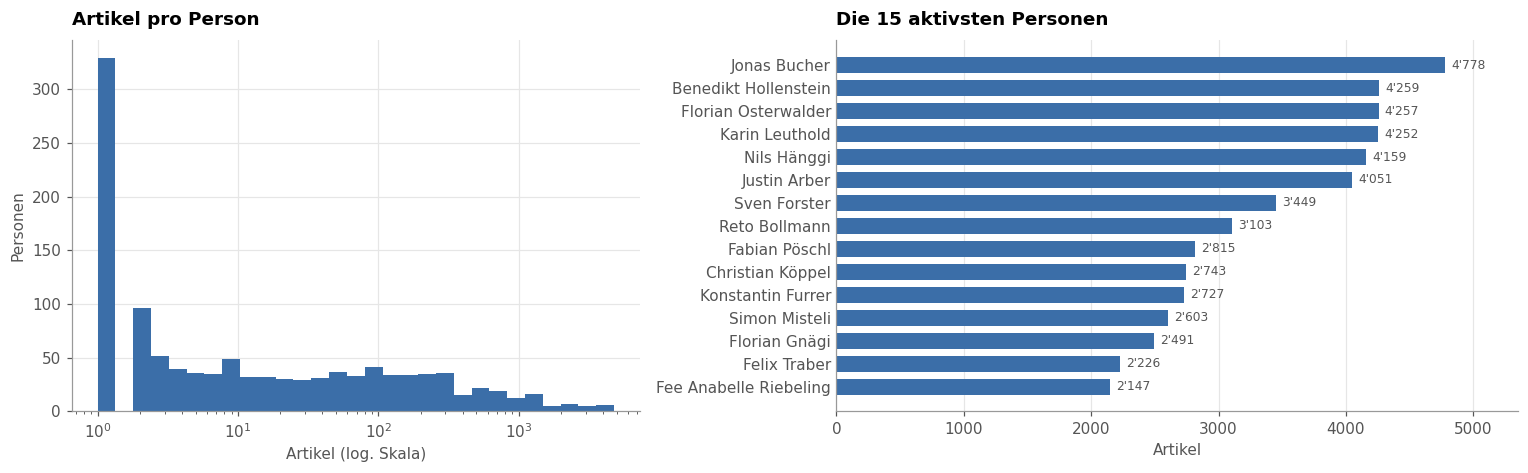

Personen: 1,149, Median 7 Artikel pro Person
Die aktivsten 10 % zeichnen 77% aller Zuordnungen
Personen mit höchstens 5 Artikeln: 48%
Nur als Kürzel bekannt: 25% der Personen


In [3]:
artikel_pro_person = personen.groupby("person")["url"].nunique().sort_values(ascending=False)
aktivste = artikel_pro_person.head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].hist(artikel_pro_person, bins=np.logspace(0, np.log10(artikel_pro_person.max() + 1), 30), color=grafik.BLAU)
axes[0].set(xscale="log", title="Artikel pro Person", xlabel="Artikel (log. Skala)", ylabel="Personen")
grafik.balken(aktivste, ax=axes[1], titel="Die 15 aktivsten Personen", xlabel="Artikel",
              farbe=[grafik.GRAU if p.startswith("kürzel:") else grafik.BLAU for p in aktivste.index[::-1]])
plt.tight_layout()
plt.show()

zehn_prozent = artikel_pro_person.head(max(1, len(artikel_pro_person) // 10)).sum() / artikel_pro_person.sum()
print(f"Personen: {len(artikel_pro_person):,}, Median {artikel_pro_person.median():.0f} Artikel pro Person")
print(f"Die aktivsten 10 % zeichnen {zehn_prozent:.0%} aller Zuordnungen")
print(f"Personen mit höchstens 5 Artikeln: {(artikel_pro_person <= 5).mean():.0%}")
print(f"Nur als Kürzel bekannt: {1 - verzeichnis['aufgeloest'].mean():.0%} der Personen")

Die Arbeit ist sehr ungleich verteilt. Die aktivsten 10 % der 1'149 Personen zeichnen 77 % aller Zuordnungen, und knapp die Hälfte
hat höchstens fünf Artikel. Das sind vermutlich Praktikantinnen, freie Mitarbeitende oder Personen, die nur kurz bei 20 Minuten waren.
Ein Viertel der Personen kennen wir nur als Kürzel. Unter den aktivsten ist aber kaum eines, weil die Kürzel vor allem 2020 bis 2022 vorkommen.

Für das Netz der thematischen Nähe setzen wir deshalb eine Mindestzahl von 30 Artikeln. Mit wenigen Artikeln wäre das Themenprofil einer Person Zufall.

## 2. Co-Autorschaft: Wer arbeitet mit wem?

Gemeinsam gezeichnete Artikel zeigen, wer tatsächlich zusammenarbeitet. Aus der Struktur des Netzes lässt sich ablesen,
ob die Redaktion in festen Teams arbeitet (dichte Gruppen mit wenigen Verbindungen dazwischen) oder durchmischt.

Wir erwarten, dass die meisten Artikel nur eine Person haben und das Netz deshalb dünn ist. Innerhalb der Ressorts
sollte es Teams geben und dazwischen einige Personen, die Teams verbinden.

In [4]:
K = nw.koautoren_netz(personen, artikel)
mit_kanten = K.subgraph([n for n in K if K.degree(n) > 0]).copy()
werte = nw.kennzahlen(K)
teams = nw.communities(mit_kanten)
giant = nw.groesste_komponente(mit_kanten)

print(f"Personen: {werte['knoten']:,}, davon nie mit jemandem zusammen: {werte['isolierte']:,} ({werte['isolierte'] / werte['knoten']:.0%})")
print(f"Kanten: {werte['kanten']:,}, Dichte {werte['dichte']:.4f}")
print(f"Grösste zusammenhängende Gruppe: {giant.number_of_nodes():,} Personen")
print(f"Louvain: {teams['anzahl']} Teams, Modularität {teams['modularitaet']:.2f}")

Personen: 1,149, davon nie mit jemandem zusammen: 365 (32%)
Kanten: 5,209, Dichte 0.0079
Grösste zusammenhängende Gruppe: 724 Personen
Louvain: 33 Teams, Modularität 0.58


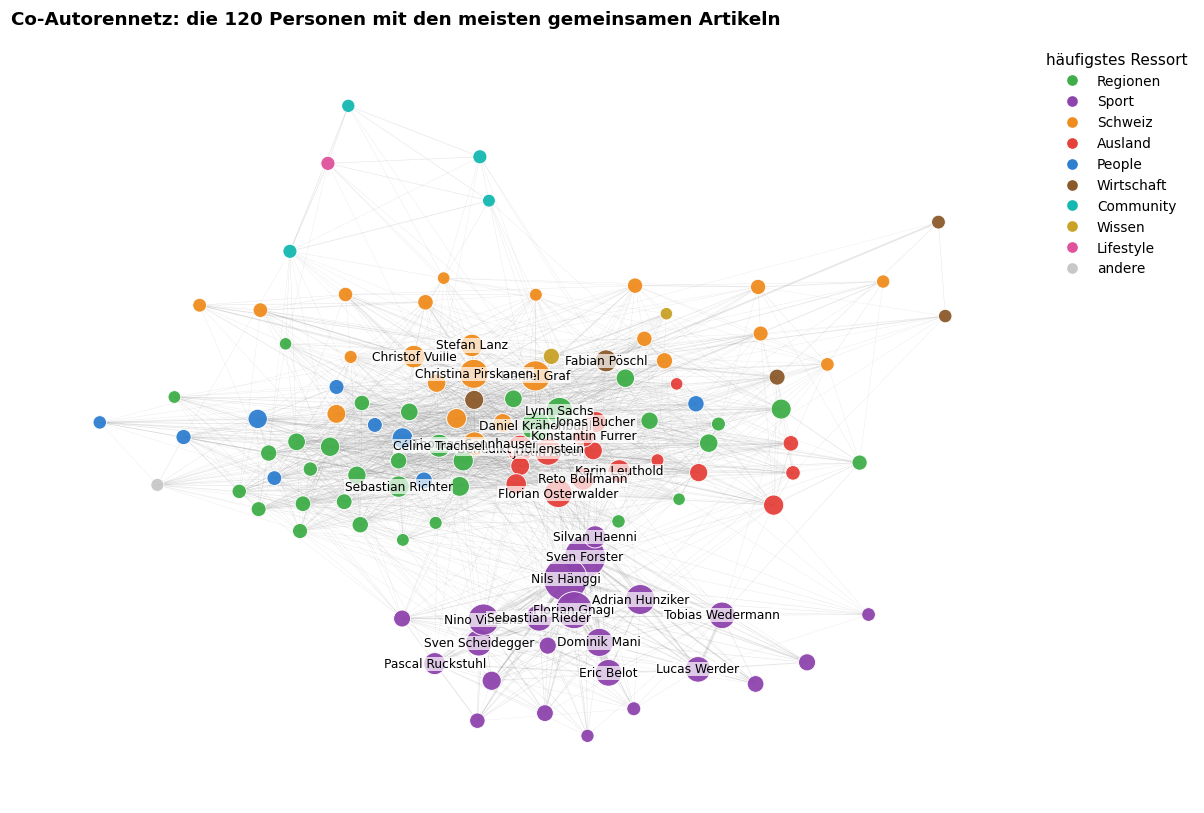

In [5]:
fig, ax = plt.subplots(figsize=(12, 9))
grafik.netz_zeichnen(giant, ax=ax, top=120, farbe="ressort", beschriftung=30, legende_titel="häufigstes Ressort",
                     titel="Co-Autorennetz: die 120 Personen mit den meisten gemeinsamen Artikeln")
plt.show()

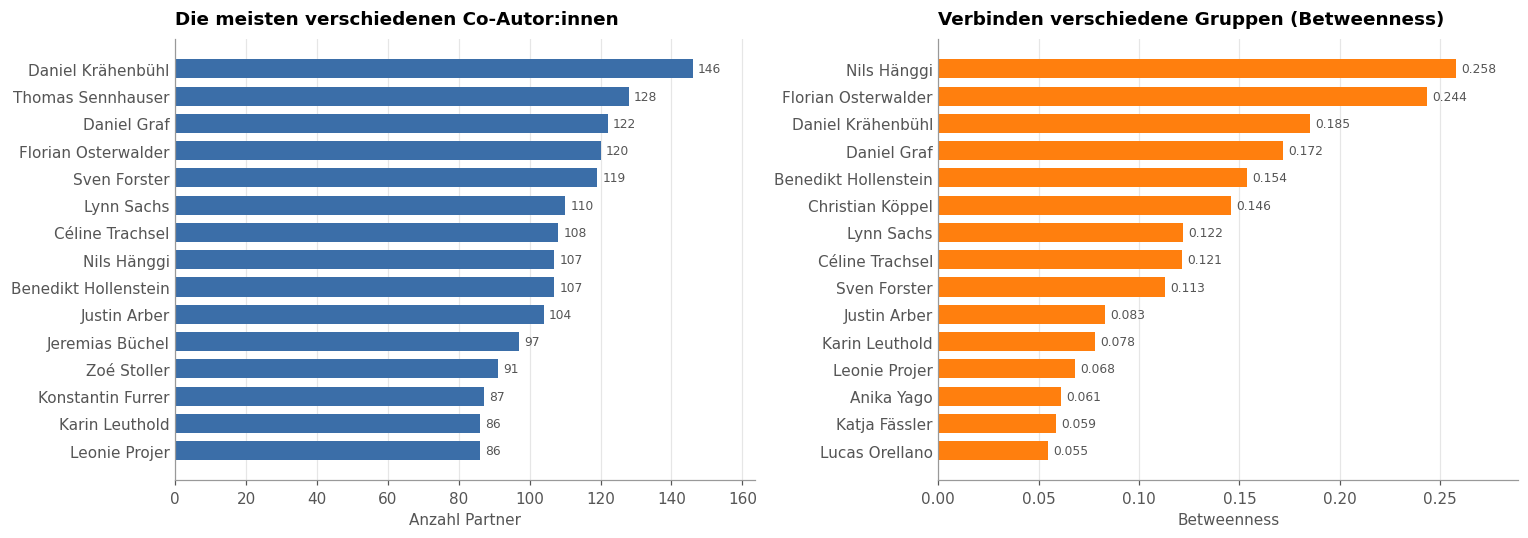

In [6]:
zentral_k = nw.zentralitaeten(mit_kanten)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
grafik.balken(zentral_k["grad"].nlargest(15), ax=axes[0], titel="Die meisten verschiedenen Co-Autor:innen",
              xlabel="Anzahl Partner", farbe=grafik.BLAU)
grafik.balken(zentral_k["betweenness"].nlargest(15), ax=axes[1], fmt="{:.3f}",
              titel="Verbinden verschiedene Gruppen (Betweenness)", xlabel="Betweenness", farbe=grafik.PALETTE[1])
plt.tight_layout()
plt.show()

Ressort-Assortativität: 0.355 (Zufall -0.004, p = 0.005)


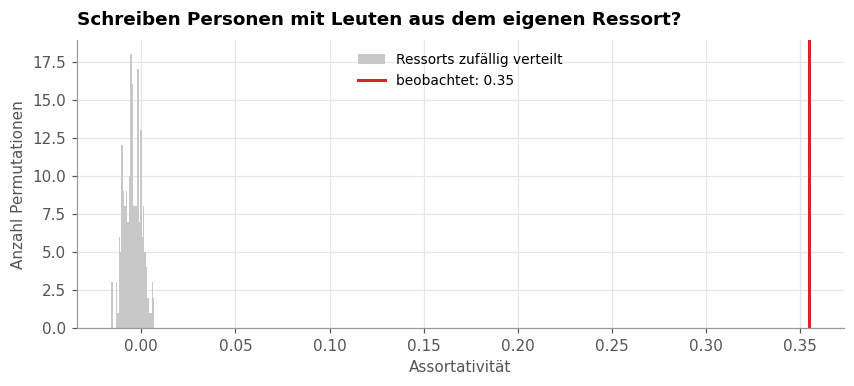

In [7]:
test = nw.assortativitaet_test(mit_kanten, "ressort")
print(f"Ressort-Assortativität: {test['beobachtet']:.3f} (Zufall {test['null_mittel']:.3f}, p = {test['p_wert']:.3f})")

fig, ax = plt.subplots(figsize=(9, 3.4))
grafik.permutation_zeichnen(test, ax=ax, titel="Schreiben Personen mit Leuten aus dem eigenen Ressort?")
plt.show()

Ein Drittel der Personen (32 %) hat im ganzen Zeitraum nie zusammen mit jemand anderem gezeichnet. Das Netz ist entsprechend dünn
(Dichte 0,008). Die übrigen Personen hängen zum grössten Teil zusammen: 724 Personen bilden eine zusammenhängende Gruppe.

Die Zeichnung zeigt zwei Bereiche. Das Sportteam liegt deutlich abgesetzt rechts oben, mit Nils Hänggi und Sven Forster in der Mitte.
Regionen, Ausland und Schweiz bilden dagegen einen gemeinsamen Kern. Diese Ressorts arbeiten offenbar eng zusammen, wahrscheinlich
über einen gemeinsamen Newsdesk. Die Assortativität nach Ressort liegt bei 0,36 und damit klar über dem Zufall (p = 0,005, der
kleinste mögliche Wert bei 200 Permutationen). Sie ist aber weit von 1 entfernt. Teams sind also an Ressorts gebunden, aber nicht streng.

Die meisten verschiedenen Co-Autor:innen haben Daniel Krähenbühl, Daniel Graf und Florian Osterwalder (120 bis 146). Die höchste
Betweenness hat Nils Hänggi, weil er das Sportteam mit dem Rest verbindet. Welche Rolle diese Personen in der Redaktion haben,
etwa Desk oder Ressortleitung, können wir aus den Daten nicht ablesen.

Co-Autorschaft ist nur ein Ausschnitt der Zusammenarbeit. Redigieren, Recherchehilfe oder Fotos stehen nicht in der Byline.
Viele Einzelautor:innen bedeuten deshalb nicht, dass wenig zusammengearbeitet wird.

## 3. Thematische Nähe: Wer schreibt worüber?

Auch Personen, die nie zusammen schreiben, können dieselben Themen bearbeiten. Wir beschreiben jede Person durch die
Keywords ihrer Artikel und verbinden sie mit den zehn Personen, deren Profil am ähnlichsten ist. Die Communities in
diesem Netz sind thematische Gruppen. Uns interessiert, ob sie sich mit den Ressorts decken.

Wir berücksichtigen nur Personen mit mindestens `MIN_ARTIKEL` Artikeln, sonst hängt das Profil vom Zufall ab.
Wir erwarten klare Gruppen für Sport, Ausland und die Regionen und einige Personen, die über mehrere Gebiete schreiben.

395 Personen mit mindestens 30 Artikeln
13 Themengruppen, Modularität 0.82


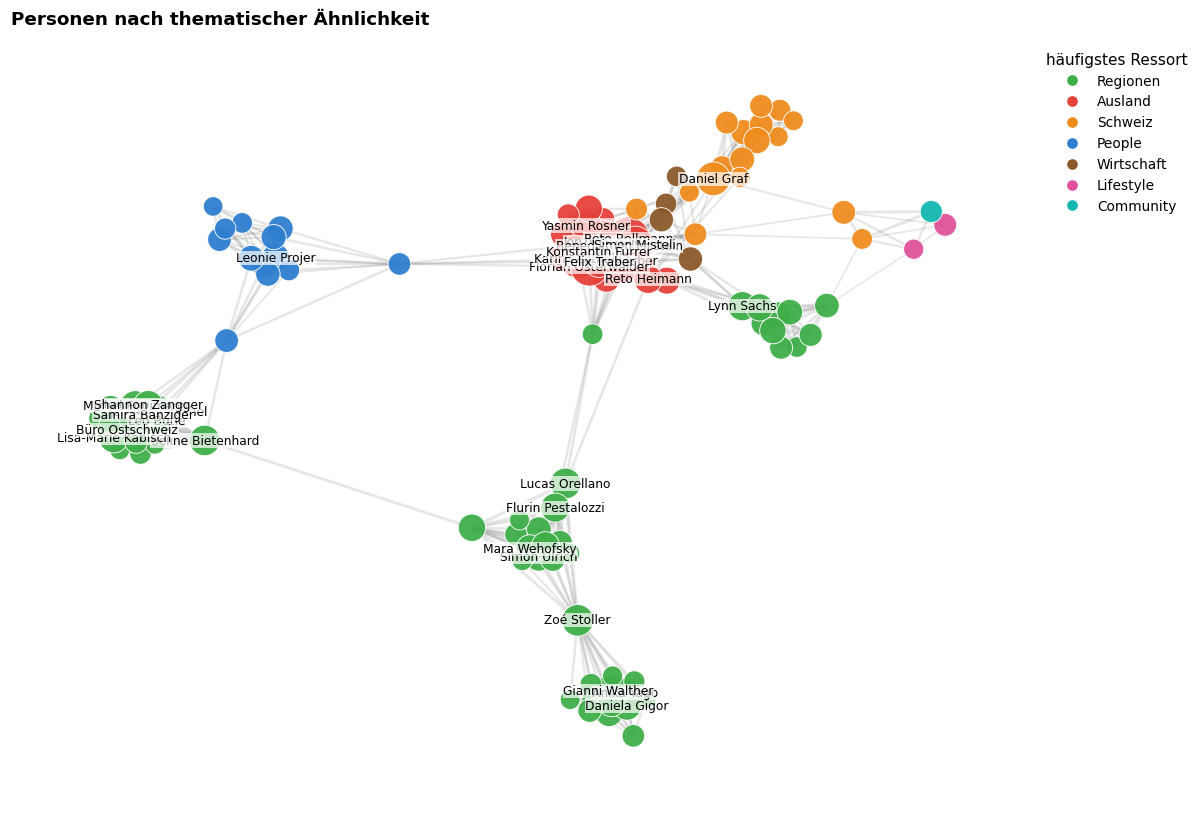

In [8]:
T = nw.autoren_themen_netz(personen, keywords, artikel, min_artikel=MIN_ARTIKEL)
gruppen = nw.communities(T)
print(f"{T.number_of_nodes()} Personen mit mindestens {MIN_ARTIKEL} Artikeln")
print(f"{gruppen['anzahl']} Themengruppen, Modularität {gruppen['modularitaet']:.2f}")

fig, ax = plt.subplots(figsize=(12, 9))
grafik.netz_zeichnen(T, ax=ax, top=150, farbe="ressort", beschriftung=30, legende_titel="häufigstes Ressort",
                     titel="Personen nach thematischer Ähnlichkeit")
plt.show()

In [9]:
tabelle = nw.community_tabelle(T, gruppen["gruppen"], top=4)
tabelle["typische Keywords"] = [
    ", ".join(pd.Series(", ".join(T.nodes[p].get("top_keywords", "") for p in g).split(", ")).value_counts().index[:6])
    for g in gruppen["gruppen"]
]
tabelle.head(10).rename(columns={"groesse": "Personen", "ressort": "häufigstes Ressort", "top": "zentrale Personen"})

,community,Personen,häufigstes Ressort,zentrale Personen,typische Keywords
0,0,68,Ausland,"Jonas Bucher, Justin Arber, Reto Bollmann, Benedikt Hollenstein","Donald Trump, Schweiz, Russland, Ukraine, Polizei, USA"
1,1,50,Sport,"Dominik Mani, Florian Gnägi, Sven Forster, Nils Hänggi","YB, Nati, Marco Odermatt, FC Basel, FCB, GC"
2,2,41,People,"Leonie Projer, Gina Sergi, Janelle Oldani, Katrin Ofner","Prinz Harry, Meghan, Song, Sängerin, Film, Instagram"
3,3,41,Lifestyle,"Anja Zingg, Meret Steiger, Deborah Gonzalez, Monika Abdel Meseh","Beziehung, Tiktok, Sex, Kind, Lade hier deine Bild, Tipps"
4,4,31,Regionen,"Jeremias Büchel, Leo Butie, Michel Eggimann, Seline Bietenhard","St. Gallen, Kantonspolizei St. Gallen, Kantonspolizei Thurgau, Auto, Kantonspolizei Graubünden, ..."
5,5,28,Schweiz,"Daniel Graf, Christina Pirskanen, Stefan Lanz, Daniel Waldmeier","Bundesrat, SVP, BAG, Schweiz, Nationalrat, Alain Berset"
6,6,27,Regionen,"Lucas Orellano, Flurin Pestalozzi, Simon Ulrich, Mara Wehofsky","Bern, Kantonspolizei Bern, Kanton Bern, Kantonspolizei Solothurn, Auto, Brand"
7,7,26,Regionen,"Zoé Stoller, Daniela Gigor, Anika Yago, Gianni Walther","Luzern, Luzerner Polizei, Stadt Luzern, Kanton Luzern, Auto, Zuger Polizei"
8,8,26,Regionen,"Lukas Hausendorf, Jeanne Dutoit, Ajla Mehanovic, Vanessa Travasci","Basel, BL, Basel-Stadt, Polizei, Kantonspolizei Basel-Stadt, Baselbieter Polizei"
9,9,24,Regionen,"Lynn Sachs, Daniel Krähenbühl, Monira Djurdjevic, Céline Trachsel","Kantonspolizei Zürich, Zürich, Stadtpolizei Zürich, Winterthur, Kantonspolizei Aargau, Polizei"


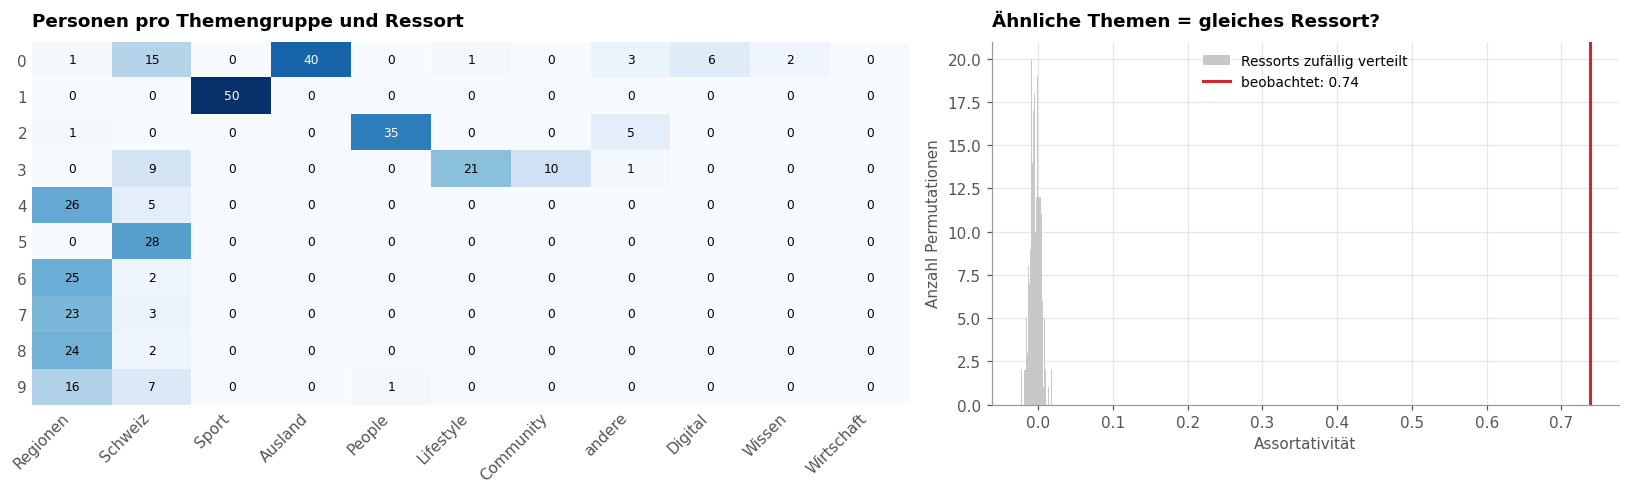

Anteil des häufigsten Ressorts pro Themengruppe: Mittel 82%
Ressort-Assortativität: 0.739 (Zufall -0.004, p = 0.005)


In [10]:
zusammensetzung = pd.crosstab(
    pd.Series({p: T.nodes[p]["community"] for p in T}, name="Themengruppe"),
    pd.Series({p: T.nodes[p].get("ressort", "andere") for p in T}, name="Ressort"),
).loc[lambda d: d.index < 10]
zusammensetzung = zusammensetzung.loc[:, zusammensetzung.sum().sort_values(ascending=False).index]
test_t = nw.assortativitaet_test(T, "ressort")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
grafik.heatmap(zusammensetzung, ax=axes[0], fmt="{:.0f}", titel="Personen pro Themengruppe und Ressort")
grafik.permutation_zeichnen(test_t, ax=axes[1], titel="Ähnliche Themen = gleiches Ressort?")
plt.tight_layout()
plt.show()

reinheit = (zusammensetzung.max(axis=1) / zusammensetzung.sum(axis=1))
print(f"Anteil des häufigsten Ressorts pro Themengruppe: Mittel {reinheit.mean():.0%}")
print(f"Ressort-Assortativität: {test_t['beobachtet']:.3f} (Zufall {test_t['null_mittel']:.3f}, p = {test_t['p_wert']:.3f})")

Hier sind die Ressorts viel deutlicher sichtbar als bei der Co-Autorschaft. Die 395 Personen mit mindestens 30 Artikeln zerfallen
in 13 Themengruppen mit hoher Modularität (0,82). Im Mittel gehören 82 % einer Gruppe zum selben Ressort, und die Assortativität
liegt bei 0,74. Wer über ähnliche Themen schreibt, sitzt also meistens im selben Ressort.

Interessant ist die Aufteilung der Regionen. Sie zerfallen nicht nach Thema, sondern nach Gebiet: Ostschweiz, Bern/Solothurn,
Zentralschweiz, Basel und Zürich bilden je eigene Gruppen, erkennbar an den Polizeikorps in den typischen Keywords. Das spiegelt
die Regionalredaktionen. Die Ausland-Gruppe hat dagegen auch „Schweiz“ und „Polizei“ unter den typischen Keywords. Sie schreibt
offenbar auch über allgemeine News.

In der Lifestyle-Gruppe steht „Lade hier deine Bild“ unter den Keywords. Das ist ein Textbaustein der Seite (Aufruf zum Hochladen
von Bildern), den die Keyword-Extraktion nicht herausgefiltert hat. Er gehört auf die Liste der Stoppwörter.

## 4. Welche Themen bewegen das Publikum?

Likes, Shares und Kommentare stehen für verschiedene Arten von Resonanz: Zustimmung, Weiterempfehlung und Diskussion.
Pro Keyword vergleichen wir den Median mit dem Median aller Artikel. Wir verwenden nur Artikel ab Juni 2020 ohne
Liveticker, Kommentare nur bei offener Kommentarfunktion, und nur Keywords mit mindestens `MIN_N` Artikeln.

Wir erwarten, dass Politik und Corona-Massnahmen am meisten kommentiert, Tiere und Kurioses am meisten gelikt und
Service- und Gesundheitsthemen am meisten geteilt werden.

Keywords mit mindestens 50 Artikeln: 3,222
Median aller Artikel: 476 Likes, 49 Shares, 32 Kommentare


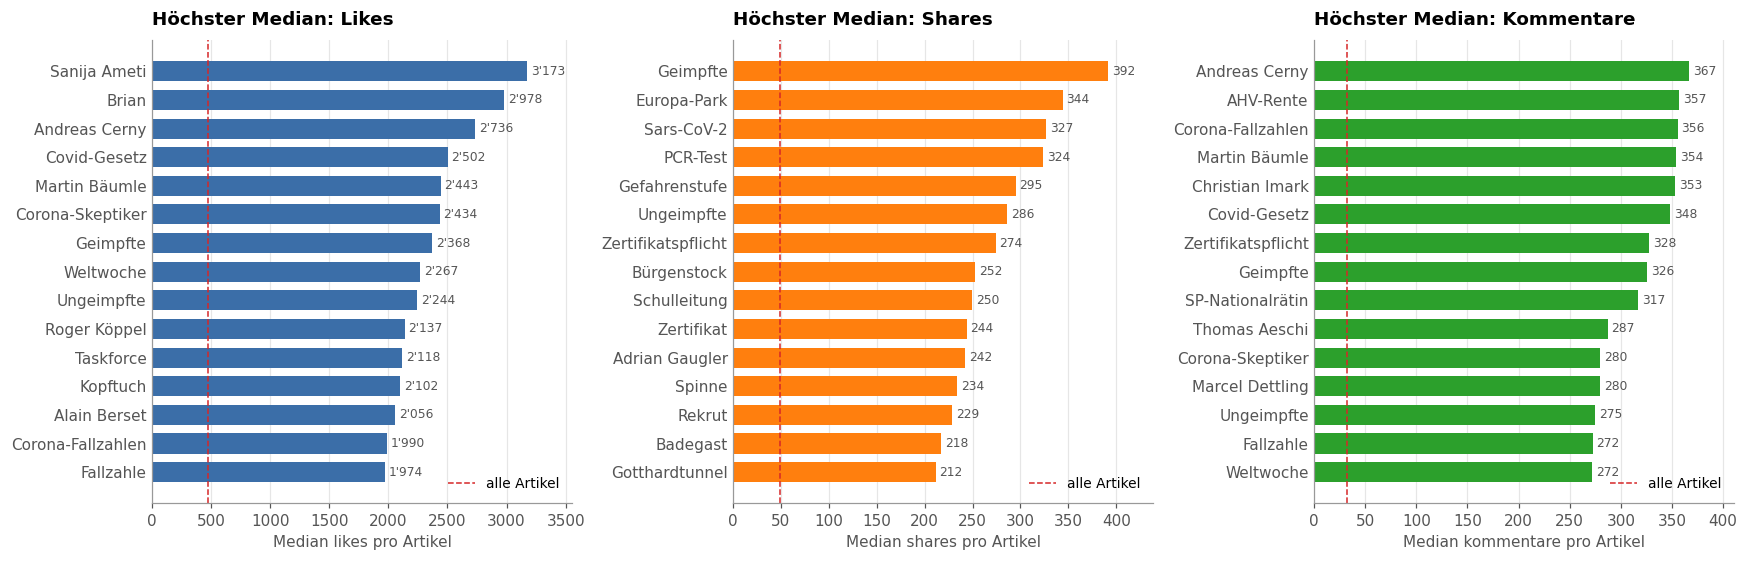

In [11]:
kw = keywords.merge(reaktiv[["url", "likes", "shares", "kommentare"]], on="url")
gesamt = reaktiv[daten.REAKTIONEN].median()
pro_kw = kw.groupby("keyword").agg(artikel=("url", "nunique"), likes=("likes", "median"),
                                   shares=("shares", "median"), kommentare=("kommentare", "median"))
pro_kw = pro_kw[pro_kw["artikel"] >= MIN_N].astype(float)
print(f"Keywords mit mindestens {MIN_N} Artikeln: {len(pro_kw):,}")
print(f"Median aller Artikel: {gesamt['likes']:.0f} Likes, {gesamt['shares']:.0f} Shares, {gesamt['kommentare']:.0f} Kommentare")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, spalte, farbe in zip(axes, daten.REAKTIONEN, [grafik.BLAU, grafik.PALETTE[1], grafik.PALETTE[2]]):
    grafik.balken(pro_kw[spalte].nlargest(15), ax=ax, titel=f"Höchster Median: {spalte.capitalize()}",
                  xlabel=f"Median {spalte} pro Artikel", farbe=farbe,
                  referenz=float(gesamt[spalte]), referenz_label="alle Artikel")
plt.tight_layout()
plt.show()

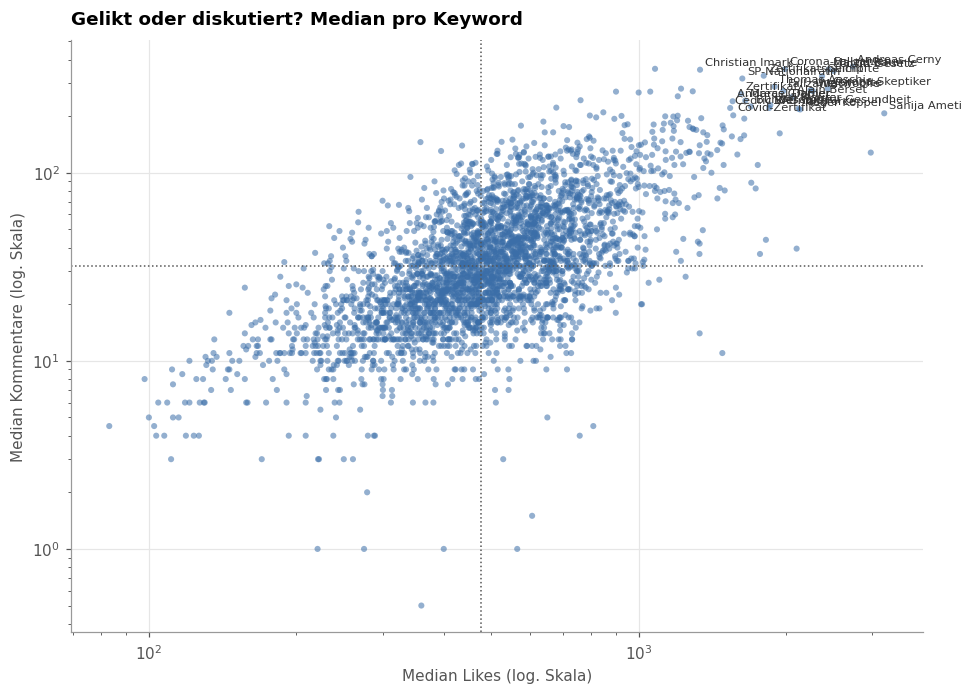

Viele Kommentare im Verhältnis zu den Likes: US-Zölle, AHV-Rente, Ölpreis, Krankenkassenprämie, Lohnerhöhung, Gesundheitskost, Christian Fichter, Junglenker
Viele Likes im Verhältnis zu den Kommentaren: Rega-Crew, Tatverdächtiger, Vermisstmeldung, Kantonspolizei Appenzell Ausserrhoden, Zugunglück, Streamingstart, Messerattacke, Schussabgabe


In [12]:
pro_kw_k = pro_kw.dropna(subset=["kommentare"])
pro_kw_k = pro_kw_k[(pro_kw_k["likes"] > 0) & (pro_kw_k["kommentare"] > 0)]

fig, ax = plt.subplots(figsize=(10, 7))
grafik.streu_beschriftet(pro_kw_k, "likes", "kommentare", ax=ax, beschriftung=25, log=True,
                         xlabel="Median Likes (log. Skala)", ylabel="Median Kommentare (log. Skala)",
                         titel="Gelikt oder diskutiert? Median pro Keyword")
ax.axvline(float(gesamt["likes"]), color=grafik.DUNKELGRAU, linestyle=":", linewidth=1)
ax.axhline(float(gesamt["kommentare"]), color=grafik.DUNKELGRAU, linestyle=":", linewidth=1)
plt.show()

verhaeltnis = (pro_kw_k["kommentare"] / pro_kw_k["likes"]).sort_values()
print("Viele Kommentare im Verhältnis zu den Likes:", ", ".join(verhaeltnis.index[-8:][::-1]))
print("Viele Likes im Verhältnis zu den Kommentaren:", ", ".join(verhaeltnis.index[:8]))

Die Kommentare entsprechen unserer Erwartung: Am meisten diskutiert werden Corona-Massnahmen (Covid-Gesetz, Zertifikatspflicht,
Geimpfte), Politikerinnen und Politiker sowie die AHV-Rente. Bei den Likes lagen wir falsch. Nicht Tiere und Kurioses werden am
meisten gelikt, sondern polarisierende Personen (Sanija Ameti, Andreas Cerny, Roger Köppel) und wieder Corona. Ein Like heisst
hier wohl eher „ich stimme zu“ als „gefällt mir“. Geteilt werden vor allem Service-Themen (PCR-Test, Zertifikat, Gefahrenstufe,
Gotthardtunnel, Europa-Park). Das passt zur Erwartung.

Das Verhältnis von Kommentaren zu Likes zeigt zwei Typen von Themen. Bei Geldthemen (US-Zölle, AHV-Rente, Krankenkassenprämie,
Lohnerhöhung) wird viel diskutiert. Bei Polizeimeldungen (Vermisstmeldung, Messerattacke, Zugunglück) wird eher gelikt als kommentiert.

Zwei Einschränkungen sind wichtig. Viele Corona-Begriffe stammen aus 2020 und 2021, als die Reaktionen allgemein höher waren
(Notebook 01, Abschnitt 7). Ein Teil ihres Vorsprungs kommt also von der Zeit, nicht vom Thema. Und Reaktionen hängen von der
Platzierung auf der Startseite ab, die wir nicht kennen.

## 5. Reaktionen und Kommentarsperren pro Themencluster

Einzelne Keywords sind laut. Robuster ist der Vergleich ganzer Themencluster aus dem Keyword-Netz. So verbinden wir
die Themenstruktur aus Notebook 02 mit der Resonanz. Zusätzlich zeigen wir, in welchen Clustern die Redaktion die
Kommentarfunktion am häufigsten sperrt.

Wir erwarten deutliche Unterschiede: Unfälle und Verbrechen oft gesperrt, Politik viel kommentiert, People und Tiere viel gelikt.

16 Cluster mit mindestens 500 Artikeln


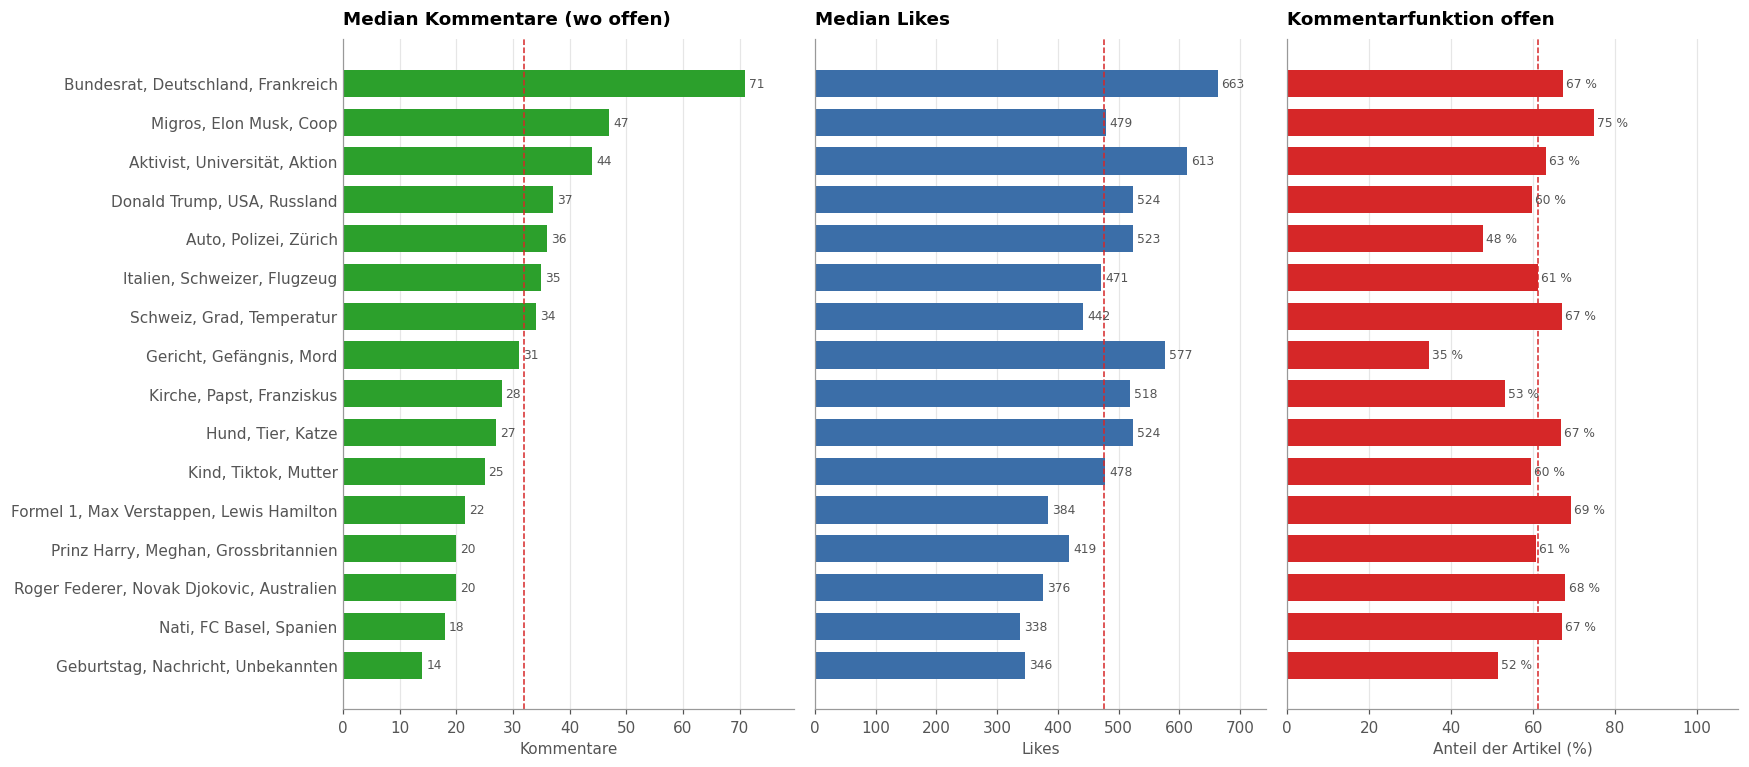

In [13]:
G = nw.keyword_netz(keywords, artikel, min_df=max(5, MIN_N // 2), min_anzahl=2)
cluster = nw.communities(G)
namen = nw.community_tabelle(G, cluster["gruppen"], top=3).set_index("community")["top"]
zuordnung = pd.Series(nw.nx.get_node_attributes(G, "community"), name="community")
kw_c = keywords.merge(zuordnung, left_on="keyword", right_index=True).drop_duplicates(["url", "community"])
kw_c = kw_c.merge(reaktiv[["url", "likes", "shares", "kommentare"]], on="url")
pro_c = kw_c.groupby("community").agg(
    artikel=("url", "nunique"), likes=("likes", "median"), shares=("shares", "median"),
    kommentare=("kommentare", "median"), offen=("kommentare", lambda s: s.notna().mean()),
)
pro_c = pro_c[pro_c["artikel"] >= 500].astype(float).sort_values("kommentare", ascending=False)
pro_c.index = [namen[i] for i in pro_c.index]
print(f"{len(pro_c)} Cluster mit mindestens 500 Artikeln")

# Alle drei Teile in derselben Reihenfolge, damit eine Zeile ein Cluster ist
fig, axes = plt.subplots(1, 3, figsize=(16, max(4, 0.38 * len(pro_c) + 1)), sharey=True)
grafik.balken(pro_c["kommentare"], ax=axes[0], titel="Median Kommentare (wo offen)", xlabel="Kommentare",
              referenz=float(reaktiv["kommentare"].median()), farbe=grafik.PALETTE[2])
grafik.balken(pro_c["likes"], ax=axes[1], titel="Median Likes", xlabel="Likes",
              referenz=float(reaktiv["likes"].median()), farbe=grafik.BLAU)
grafik.balken(pro_c["offen"] * 100, ax=axes[2], fmt="{:.0f} %", titel="Kommentarfunktion offen", xlabel="Anteil der Artikel (%)",
              referenz=reaktiv["kommentare"].notna().mean() * 100, farbe=grafik.PALETTE[3])
axes[2].set_xlim(0, 110)
for ax in axes[1:]:
    ax.tick_params(labelleft=False)
plt.tight_layout()
plt.show()

Zwischen den Clustern gibt es deutliche Unterschiede. Am meisten kommentiert wird der Politik-Cluster (Bundesrat, Deutschland,
Frankreich) mit einem Median von 71 Kommentaren, mehr als doppelt so viel wie alle Artikel (32). Er hat auch die meisten Likes.
Sport (Nati, Formel 1, Federer) und People (Prinz Harry) werden wenig kommentiert und wenig gelikt.

Die Sperrquote zeigt die Entscheidungen der Redaktion. Am seltensten offen sind die Cluster zu Gericht und Verbrechen (35 %) und
zu Unfällen (Auto, Polizei, Zürich: 48 %), wie erwartet. Bemerkenswert ist, dass der Gericht-Cluster trotzdem viele Likes bekommt.
Das Publikum reagiert, darf aber nicht diskutieren.

Für H4 heisst das: Die Themen unterscheiden sich klar in der Resonanz und darin, ob überhaupt diskutiert werden darf. Die Namen der
Cluster haben wir aus ihren drei stärksten Keywords gebildet. Das ist eine Vereinfachung.

## 6. Export für Gephi

Das Co-Autorennetz und das Netz der thematischen Nähe speichern wir als `.gexf` und CSV in `Graphen/`.

In [14]:
nw.communities(K)
for name, graph in {"autoren_koautoren": K, "autoren_themen": T}.items():
    nw.exportieren(graph, GRAPHEN / name)
    print(f"{name}: {graph.number_of_nodes():,} Knoten, {graph.number_of_edges():,} Kanten")

autoren_koautoren: 1,149 Knoten, 5,209 Kanten
autoren_themen: 395 Knoten, 3,034 Kanten


## Gesamtreflexion

H4 hat zwei Teile, und beide werden gestützt, wenn auch unterschiedlich stark. Bei der Zusammenarbeit sind die Teams an Ressorts
gebunden (Assortativität 0,36), aber Regionen, Ausland und Schweiz arbeiten eng zusammen. Nur der Sport bildet ein klar
abgetrenntes Team. Bei den Themen ist die Bindung an die Ressorts viel stärker (0,74), und die Regionen teilen sich nach Gebiet auf.
Die Themencluster unterscheiden sich deutlich in Likes, Kommentaren und darin, wie oft die Redaktion die Kommentare sperrt.

Grenzen: 2020 sind die Personen wegen der Kürzel unvollständig. Co-Autorschaft zeigt nur einen Teil der Zusammenarbeit. Reaktionen
gibt es erst ab Juni 2020, die Zählweise ändert sich über die Jahre, und die Platzierung auf der Seite kennen wir nicht.